# 02 - Plane fit and individual cohesion

This notebook runs on the **synthetic** data in `00_Inputs/synthetic/` (true plane: `c = 10 MPa`, `phi = 22 deg`, with
6 % scatter in the peak). It repeats what `00_gera_params.py` does, in a few lines.

## Step A - one common envelope

Each foliation specimen gives one point `(sn, tau)`. A straight line `tau = c + sn tan(phi)` is fitted by least squares
to all specimens marked `use_plane_fit = yes`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
syn = Path("..") / "00_Inputs" / "synthetic"
if not (syn / "targets.csv").exists():
    import subprocess, sys
    subprocess.run([sys.executable, "make_synthetic_data.py"], cwd=syn, check=True)
t = pd.read_csv(syn / "targets.csv")
fit = t[t.use_plane_fit == "yes"].copy()
fit[["id_ita", "sigma3_target_MPa", "anisotropy_angle_deg", "dev_peak_MPa", "sigma_n_plane_MPa", "tau_plane_MPa"]]

,id_ita,sigma3_target_MPa,anisotropy_angle_deg,dev_peak_MPa,sigma_n_plane_MPa,tau_plane_MPa
0,ITA901,3.0,28.0,113.389,91.398,47.002
1,ITA902,3.0,41.0,37.183,24.179,18.411
2,ITA903,6.0,33.0,71.149,56.044,32.499
3,ITA904,6.0,47.0,37.537,23.459,18.723
4,ITA905,6.0,58.0,36.415,16.226,16.365
5,ITA906,12.0,36.0,74.283,60.619,35.324
6,ITA907,12.0,52.0,42.367,28.059,20.555
7,ITA908,12.0,44.0,52.525,39.179,26.246
8,ITA909,24.0,40.0,76.510,68.898,37.674
9,ITA910,24.0,63.0,61.933,36.765,25.052


common fit: c = 9.22 MPa, phi = 22.65 deg, tan(phi) = 0.4173, R2 = 1.00   (true: 10 / 22)


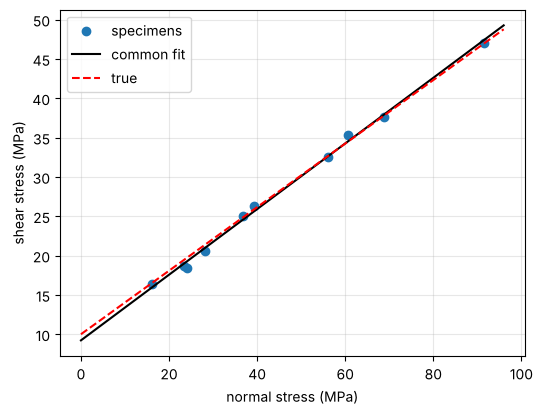

In [2]:
tanphi, c0 = np.polyfit(fit.sigma_n_plane_MPa, fit.tau_plane_MPa, 1)
phi0 = np.degrees(np.arctan(tanphi))
r2 = np.corrcoef(fit.sigma_n_plane_MPa, fit.tau_plane_MPa)[0, 1]**2
print(f"common fit: c = {c0:.2f} MPa, phi = {phi0:.2f} deg, tan(phi) = {tanphi:.4f}, R2 = {r2:.2f}   (true: 10 / 22)")

x = np.linspace(0, fit.sigma_n_plane_MPa.max()*1.05, 50)
plt.figure(figsize=(6, 4.5))
plt.plot(fit.sigma_n_plane_MPa, fit.tau_plane_MPa, "o", label="specimens")
plt.plot(x, c0 + x*tanphi, "k-", label="common fit"); plt.plot(x, 10 + x*np.tan(np.radians(22)), "r--", label="true")
plt.xlabel("normal stress (MPa)"); plt.ylabel("shear stress (MPa)"); plt.legend(); plt.grid(alpha=.3); plt.show()

`tan(phi)` is simply the **slope** of the line, and `c` is where it crosses the vertical axis.
In this synthetic set the points fall very close to the line (R2 near 1), because the stress range is wide and the scatter is small. Real data scatter more, and the scatter around the line is the part that a single pair `(c, phi)` cannot explain.

## Step B - individual cohesion

One test gives one point, which is one equation. So, per specimen, **only one** parameter can be adjusted.
We keep `phi` from the common fit and compute the cohesion that makes the line pass exactly through the point:

`c_i = tau_i - sn_i tan(phi)`

This is equal to the common `c` plus the residual of the point to the line. The mean of the `c_i` is the common `c`.

In [3]:
fit["c_i"] = fit.tau_plane_MPa - fit.sigma_n_plane_MPa*tanphi
fit["residual"] = fit.c_i - c0
print(fit[["id_ita", "sigma3_target_MPa", "anisotropy_angle_deg", "c_i", "residual"]].round(2).to_string(index=False))
print("mean of c_i:", round(fit.c_i.mean(), 2), "  common c:", round(c0, 2))

id_ita  sigma3_target_MPa  anisotropy_angle_deg   c_i  residual
ITA901                3.0                  28.0  8.86     -0.36
ITA902                3.0                  41.0  8.32     -0.90
ITA903                6.0                  33.0  9.11     -0.11
ITA904                6.0                  47.0  8.93     -0.29
ITA905                6.0                  58.0  9.59      0.37
ITA906               12.0                  36.0 10.03      0.80
ITA907               12.0                  52.0  8.84     -0.38
ITA908               12.0                  44.0  9.90      0.67
ITA909               24.0                  40.0  8.92     -0.30
ITA910               24.0                  63.0  9.71      0.49
mean of c_i: 9.22   common c: 9.22


**Caution (circularity).** With `c_i` the model reproduces the lab peak **by construction**. It cannot be used as
a validation of the plane strength. What remains to be checked is the rest of the curve (stiffness, post-peak).

## Step C - one run, then a correction

Run the model once with `c_i`. If the simulated peak `D_model` differs from the lab peak `D_lab` by more than a few
percent, correct with the sensitivity of the previous notebook:

`c_new = c_i + (D_lab - D_model) / (dD/dc)`

In [4]:
def dDdc(dip, phi_deg):
    th = np.radians(dip); t = np.tan(np.radians(phi_deg))
    return 1/(np.sin(th)*np.cos(th) - np.cos(th)**2*t)

# example: a run that came out 3 MPa below the lab peak, in a specimen with dip 40 deg
D_lab, D_model, dip = 75.0, 72.0, 40.0
c_i = 9.0
print("c_new =", round(c_i + (D_lab - D_model)/dDdc(dip, phi0), 2), "MPa")

c_new = 9.74 MPa


The repository tools do the same with the real files: `python 00_gera_params.py --dados synthetic --saida synthetic/params --individual c`.
See the README, section Quick start.